In [ ]:
!unzip "Metal Surface Defects Data.zip" -d data

Archive:  Metal Surface Defects Data.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of Metal Surface Defects Data.zip or
        Metal Surface Defects Data.zip.zip, and cannot find Metal Surface Defects Data.zip.ZIP, period.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os, shutil
from collections import Counter
import copy
import time
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.transforms.functional import to_pil_image
from torchvision.utils import make_grid

import warnings
warnings.filterwarnings("ignore")

In [ ]:
INTERPOLATION_MODE = transforms.InterpolationMode.BICUBIC
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def transform_image_():
    train_transform_aug_384 = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

    return train_transform_aug_384

transform_image = transform_image_()

# Loading

In [ ]:
data_folder = "/content/data/Metal Surface Defects Data/"
train_data_folder = "/content/data/Metal Surface Defects Data/train"
# Classes of labels in our data
# Filter out non-directory files like .DS_Store
classes = sorted([d for d in os.listdir(train_data_folder) if os.path.isdir(os.path.join(train_data_folder, d))])
print(f"Classes: {classes}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/data/Metal Surface Defects Data/train'

In [ ]:
train_dataset = datasets.ImageFolder(f"{data_folder}train", transform=transform_image)
train_dataset_without_transform = datasets.ImageFolder(f"{data_folder}train")
test_dataset = datasets.ImageFolder(f"{data_folder}test", transform=transform_image)
val_dataset = datasets.ImageFolder(f"{data_folder}valid", transform=transform_image)

In [111]:
print(f"Train Dataset: {len(train_dataset)}")
print(f"test Dataset: {len(test_dataset)}")
print(f"val Dataset: {len(val_dataset)}")

Train Dataset: 1656
test Dataset: 72
val Dataset: 72


In [ ]:
"Image size" , train_dataset[0][0].shape

In [ ]:
print("Balanced Dataset")
print("Train Dataset")
for cls, idx in train_dataset.class_to_idx.items():
    print(f"{cls}: {sum(1 for label in train_dataset.targets if label == idx)}")

print("\n Test Dataset")
for cls, idx in test_dataset.class_to_idx.items():
    print(f"{cls}: {sum(1 for label in test_dataset.targets if label == idx)}")

print("\n Val Dataset")
for cls, idx in val_dataset.class_to_idx.items():
    print(f"{cls}: {sum(1 for label in val_dataset.targets if label == idx)}")

In [ ]:
def unnormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Un-normalizes a tensor for display."""
    # Clone to avoid modifying the original tensor
    tensor = tensor.clone()

    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    tensor.mul_(std).add_(mean) # tensor * std + mean
    tensor = torch.clamp(tensor, 0, 1)
    return tensor

In [ ]:
class_names = train_dataset.classes
num_classes = len(class_names)

# Number of images to show per class
images_per_class = 3

fig, axes = plt.subplots(num_classes, images_per_class, figsize=(images_per_class*3, num_classes*3))

for class_idx, class_name in enumerate(class_names):
    # Find indices for this class
    idxs = [i for i, (_, label) in enumerate(train_dataset.samples) if label == class_idx]
    # Randomly pick images
    sample_idxs = torch.randperm(len(idxs))[:images_per_class]

    for j, sample_idx in enumerate(sample_idxs):
        img, label = train_dataset[idxs[sample_idx]]

        # Convert from tensor to numpy for plotting
        img = unnormalize(img).permute(1, 2, 0)  # C,H,W -> H,W,C

        axes[class_idx, j].imshow(img)
        axes[class_idx, j].set_title(class_names[label])
        axes[class_idx, j].axis("off")

plt.tight_layout()
plt.show()

# Training Utils

In [87]:
# Defining Some functions for training and testing

class EarlyStopper:
    """
    A simple early stopper.
    """
    def __init__(self, patience=5, min_delta=0, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_metric = -np.inf if mode == 'max' else np.inf
        self.best_model_weights = None
        self.should_stop = False

    def check(self, metric, model):
        """Checks if training should stop."""
        is_better = False
        if self.mode == 'max':
            if metric > self.best_metric + self.min_delta:
                is_better = True
        else: # min mode
            if metric < self.best_metric - self.min_delta:
                is_better = True

        if is_better:
            self.best_metric = metric
            self.counter = 0
            # Save the best model weights
            self.best_model_weights = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True

        return self.should_stop

def train_model(model, train_loader, val_loader, criterion, optimizer, device, epochs=50, patience=5, verbose=1):
    """
    Reusable function to train and validate a PyTorch model.
    """
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }

    # Use 'val_acc' in 'max' mode for early stopping
    early_stopper = EarlyStopper(patience=patience, mode='max')

    start_time = time.time()

    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            # Statistics
            model.eval()
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
            model.train()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = running_corrects.double() / len(train_loader.dataset)

        # --- Validation Phase ---
        model.eval()
        running_loss = 0.0
        running_corrects = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = running_loss / len(val_loader.dataset)
        epoch_val_acc = running_corrects.double() / len(val_loader.dataset)

        # Log history
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc.item())
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc.item())

        if verbose:
            print(f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
                f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Check early stopping
        if early_stopper.check(epoch_val_acc, model):
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

    # Load best model weights
    if early_stopper.best_model_weights:
        model.load_state_dict(early_stopper.best_model_weights)

    time_elapsed = time.time() - start_time
    print(f"\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Acc: {early_stopper.best_metric:.4f}")

    return model, history

from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

def evaluate_model(model, loader, criterion, device, class_names=None):
    """Evaluates the model and computes precision, recall, F1, and plots confusion matrix."""

    model.eval()
    running_loss = 0.0
    running_corrects = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    total_loss = running_loss / len(loader.dataset)
    total_acc = running_corrects.double() / len(loader.dataset)
    precision = precision_score(all_labels, all_preds, average='macro')
    recall = recall_score(all_labels, all_preds, average='macro')
    f1 = f1_score(all_labels, all_preds, average='macro')

    print(f"Loss: {total_loss:.4f}")
    print(f"Accuracy: {total_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")

    # ✅ Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)

    # If class names not given, use numeric labels
    if class_names is None:
        class_names = list(range(cm.shape[0]))

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap='Blues', xticks_rotation=45)
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return total_loss, total_acc.item(), precision, recall, f1

# CNN Model

In [76]:
BATCH_SIZE=32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

In [78]:
class SimpleCNN(nn.Module):
    """
    A simple CNN for classification.
    """
    def __init__(self, in_channels, num_classes):
        """
        Args:
            in_channels (int): Number of input channels (e.g., 3 for RGB, 1 for grayscale).
            num_classes (int): Number of output classes.
        """
        super(SimpleCNN, self).__init__()

        # --- Convolutional Block 1 ---
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Halves spatial dimensions

        # --- Convolutional Block 2 ---
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) # Halves spatial dimensions again

        # --- Adaptive Pooling Layer ---
        # This layer ensures the output spatial dimension is always 7x7,
        # regardless of the input image size. This makes the linear layer input consistent.
        self.adaptive_pool = nn.AdaptiveAvgPool2d((7, 7))

        # --- Classifier Head ---
        self.flatten = nn.Flatten()

        # Input features to the linear layer will be 64 (from conv2) * 7 * 7
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, num_classes)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Pass through conv blocks
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        # Pass through adaptive pooling
        x = self.adaptive_pool(x)

        # Flatten and pass through classifier
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x) # Output logits (CrossEntropyLoss applies softmax)
        # x = self.sigmoid(x)
        return x

In [79]:
def run_training_pipeline(train_dataset_, test_dataset_, val_dataset_, in_channels, num_classes, device=device):
    """
    A complete function to set up and run the training and evaluation pipeline.

    Args:
        train_dataset: The full (already augmented) training dataset.
        test_dataset: A separate dataset for final evaluation.
        in_channels (int): Number of input image channels (e.g., 3 for RGB).
        num_classes (int): Number of output classes.
    """

    # --- 1. Define Hyperparameters ---
    BATCH_SIZE = 32
    LEARNING_RATE = 0.001
    MAX_EPOCHS = 100       # Max epochs to run
    PATIENCE = 20          # Patience for your EarlyStopper
    VAL_SPLIT_RATIO = 0.2  # 20% of training data for validation

    train_loader = DataLoader(train_dataset_, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
    val_loader = DataLoader(val_dataset_, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

    # --- 4. Initialize Model, Criterion, Optimizer ---
    model = SimpleCNN(in_channels=in_channels, num_classes=num_classes).to(device)

    # Loss function (standard for multi-class classification)
    criterion = nn.CrossEntropyLoss()

    # Optimizer (Adam is a good default)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # --- 5. Run Training (using your function) ---
    print("\nStarting Training...")
    model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        epochs=MAX_EPOCHS,
        patience=PATIENCE
    )

    # --- 6. Evaluate on Test Set (using your function) ---
    print("\nEvaluating on Test Set...")
    print("-------------------------")
    evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device
    )

    print("\nPipeline finished.")
    return model, history

In [80]:
model, history = run_training_pipeline(train_dataset, test_dataset, val_dataset, 3, len(train_dataset.classes), device=device)


Starting Training...
Epoch 1/100 | Train Loss: 1.1715 Acc: 0.6093 | Val Loss: 0.5583 Acc: 0.9028
Epoch 2/100 | Train Loss: 0.4807 Acc: 0.8563 | Val Loss: 0.2091 Acc: 0.9306
Epoch 3/100 | Train Loss: 0.3010 Acc: 0.9094 | Val Loss: 0.1778 Acc: 0.9583
Epoch 4/100 | Train Loss: 0.2601 Acc: 0.9233 | Val Loss: 0.1183 Acc: 0.9444
Epoch 5/100 | Train Loss: 0.2066 Acc: 0.9444 | Val Loss: 0.1414 Acc: 0.9583
Epoch 6/100 | Train Loss: 0.1789 Acc: 0.9517 | Val Loss: 0.1576 Acc: 0.9444
Epoch 7/100 | Train Loss: 0.2009 Acc: 0.9432 | Val Loss: 0.1152 Acc: 0.9583
Epoch 8/100 | Train Loss: 0.1457 Acc: 0.9656 | Val Loss: 0.1384 Acc: 0.9583
Epoch 9/100 | Train Loss: 0.1520 Acc: 0.9614 | Val Loss: 0.0898 Acc: 0.9722
Epoch 10/100 | Train Loss: 0.1842 Acc: 0.9475 | Val Loss: 0.0919 Acc: 0.9722
Epoch 11/100 | Train Loss: 0.1151 Acc: 0.9746 | Val Loss: 0.0886 Acc: 0.9722
Epoch 12/100 | Train Loss: 0.1374 Acc: 0.9692 | Val Loss: 0.0653 Acc: 0.9722
Epoch 13/100 | Train Loss: 0.1008 Acc: 0.9740 | Val Loss: 0.112

Loss: 0.1357
Accuracy: 0.9583
Precision: 0.9615
Recall: 0.9583
F1-score: 0.9582


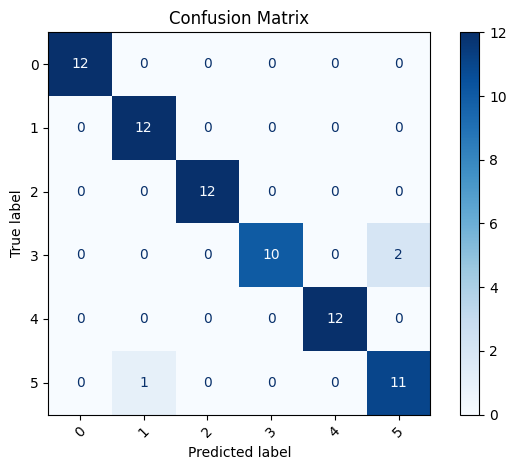

(0.13569187124570212,
 0.9583333333333333,
 0.9615384615384616,
 0.9583333333333335,
 0.9581818181818181)

In [88]:
evaluate_model(model, test_loader, nn.CrossEntropyLoss(), device)

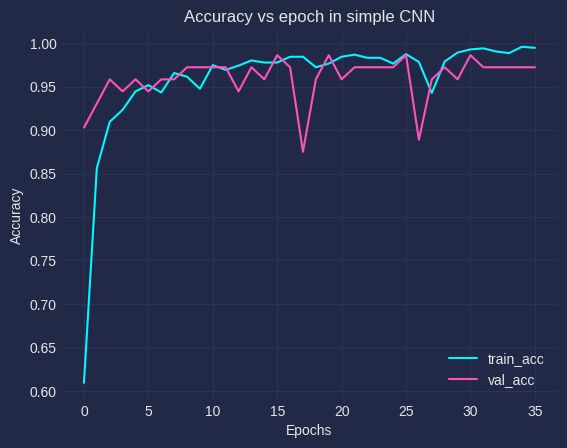

In [104]:
plt.plot(history['train_acc'], label="train_acc")
plt.plot(history['val_acc'], label="val_acc")
plt.title("Accuracy vs epoch in simple CNN")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

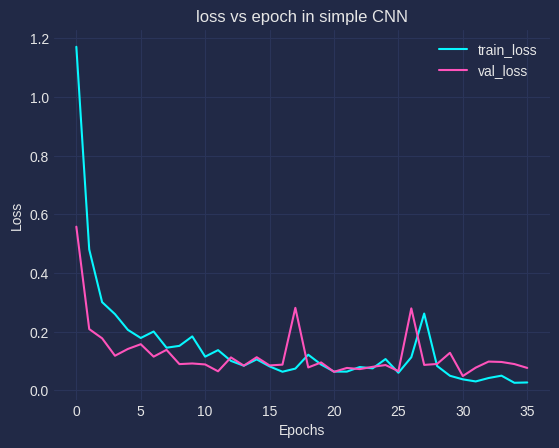

In [110]:
plt.plot(history['train_loss'], label="train_loss")
plt.plot(history['val_loss'], label="val_loss")
plt.title("loss vs epoch in simple CNN")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Adding improvements

In [90]:
def transform_image_():
    """
    Our image size is 224x224 it needs to be converted to 384x384
    """
    train_transform_aug_384 = transforms.Compose([
        transforms.RandomAffine(
            degrees=40,            # rotation
            translate=(0.1, 0.1),  # shift (10% horizontally/vertically)
            scale=(0.7, 1.0)       # zoom
        ),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])
    return train_transform_aug_384

transform_image = transform_image_()


In [93]:
class AdvancedCNN(nn.Module):
    """
    A more advanced CNN with BatchNorm & Dropout.
    """
    def __init__(self, in_channels, num_classes):
        super(AdvancedCNN, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 384 -> 192
            nn.Dropout(0.2)
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 192 -> 96
            nn.Dropout(0.3)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))  # Output 128x7x7
        self.flatten = nn.Flatten()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.classifier(x)
        # x = self.sigmoid(x)
        return x


In [94]:
def train_model(model, train_dataset, val_dataset, criterion, optimizer, device, epochs=50, patience=5, verbose=1, BATCH_SIZE=32):
    """
    Reusable function to train and validate a PyTorch model.
    """
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }

    # Use 'val_acc' in 'max' mode for early stopping
    early_stopper = EarlyStopper(patience=patience, mode='max')

    start_time = time.time()
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

    for epoch in range(epochs):

        # Apply transformations in each epoch
        train_dataset_without_transform = datasets.ImageFolder(f"{data_folder}train", transform=transform_image)
        train_loader = DataLoader(train_dataset_without_transform, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)

        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            # Statistics
            model.eval()
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
            model.train()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = running_corrects.double() / len(train_loader.dataset)

        # --- Validation Phase ---
        model.eval()
        running_loss = 0.0
        running_corrects = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = running_loss / len(val_loader.dataset)
        epoch_val_acc = running_corrects.double() / len(val_loader.dataset)

        # Log history
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc.item())
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc.item())

        if verbose:
            print(f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
                f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Check early stopping
        if early_stopper.check(epoch_val_acc, model):
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

    # Load best model weights
    if early_stopper.best_model_weights:
        model.load_state_dict(early_stopper.best_model_weights)

    time_elapsed = time.time() - start_time
    print(f"\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Acc: {early_stopper.best_metric:.4f}")

    return model, history

from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

def evaluate_model(model, loader, criterion, device, class_names=None):
    """Evaluates the model and computes precision, recall, F1, and plots confusion matrix."""

    model.eval()
    running_loss = 0.0
    running_corrects = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    total_loss = running_loss / len(loader.dataset)
    total_acc = running_corrects.double() / len(loader.dataset)
    precision = precision_score(all_labels, all_preds, average='macro')
    recall = recall_score(all_labels, all_preds, average='macro')
    f1 = f1_score(all_labels, all_preds, average='macro')

    print(f"Loss: {total_loss:.4f}")
    print(f"Accuracy: {total_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")

    # ✅ Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)

    # If class names not given, use numeric labels
    if class_names is None:
        class_names = list(range(cm.shape[0]))

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap='Blues', xticks_rotation=45)
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return total_loss, total_acc.item(), precision, recall, f1

def run_training_pipeline(train_dataset_, test_dataset_, val_dataset_, in_channels, num_classes, device=device, PATIENCE = 20 ):
    """
    A complete function to set up and run the training and evaluation pipeline.

    Args:
        train_dataset: The full (already augmented) training dataset.
        test_dataset: A separate dataset for final evaluation.
        in_channels (int): Number of input image channels (e.g., 3 for RGB).
        num_classes (int): Number of output classes.
    """

    # --- 1. Define Hyperparameters ---
    BATCH_SIZE = 32
    LEARNING_RATE = 0.001
    MAX_EPOCHS = 100       # Max epochs to run
    VAL_SPLIT_RATIO = 0.2  # 20% of training data for validation

    train_loader = DataLoader(train_dataset_, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
    val_loader = DataLoader(val_dataset_, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

    # --- 4. Initialize Model, Criterion, Optimizer ---
    model = AdvancedCNN(in_channels=in_channels, num_classes=num_classes).to(device)

    # Loss function (standard for multi-class classification)
    criterion = nn.CrossEntropyLoss()

    # Optimizer (Adam is a good default)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # --- 5. Run Training (using your function) ---
    print("\nStarting Training...")
    model, history = train_model(
        model=model,
        train_dataset=train_dataset,
        val_dataset=val_dataset,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        epochs=MAX_EPOCHS,
        patience=PATIENCE
    )

    # --- 6. Evaluate on Test Set (using your function) ---
    print("\nEvaluating on Test Set...")
    print("-------------------------")
    evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device
    )

    print("\nPipeline finished.")
    return model, history


Starting Training...
Epoch 1/100 | Train Loss: 1.1032 Acc: 0.4414 | Val Loss: 0.6762 Acc: 0.6944
Epoch 2/100 | Train Loss: 0.7538 Acc: 0.7699 | Val Loss: 0.4598 Acc: 0.7500
Epoch 3/100 | Train Loss: 0.5952 Acc: 0.8031 | Val Loss: 0.3509 Acc: 0.8611
Epoch 4/100 | Train Loss: 0.5823 Acc: 0.8207 | Val Loss: 0.6370 Acc: 0.7222
Epoch 5/100 | Train Loss: 0.5283 Acc: 0.8315 | Val Loss: 0.2659 Acc: 0.9028
Epoch 6/100 | Train Loss: 0.5587 Acc: 0.8267 | Val Loss: 0.2628 Acc: 0.9306
Epoch 7/100 | Train Loss: 0.4787 Acc: 0.8496 | Val Loss: 0.2302 Acc: 0.9444
Epoch 8/100 | Train Loss: 0.4638 Acc: 0.8647 | Val Loss: 0.2425 Acc: 0.9167
Epoch 9/100 | Train Loss: 0.4133 Acc: 0.8678 | Val Loss: 0.2355 Acc: 0.9028
Epoch 10/100 | Train Loss: 0.4027 Acc: 0.8973 | Val Loss: 0.1745 Acc: 0.9306
Epoch 11/100 | Train Loss: 0.3583 Acc: 0.8853 | Val Loss: 0.1720 Acc: 0.9444
Epoch 12/100 | Train Loss: 0.3699 Acc: 0.9016 | Val Loss: 0.3453 Acc: 0.8611
Epoch 13/100 | Train Loss: 0.3410 Acc: 0.8780 | Val Loss: 0.424

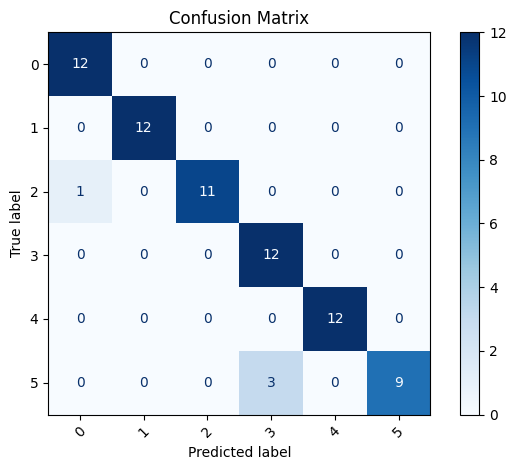


Pipeline finished.


In [95]:
advance_model_, advance_history_ = run_training_pipeline(train_dataset, test_dataset, val_dataset, 3, len(train_dataset.classes), device=device)

In [106]:
advance_model = advance_model_
advance_history =  advance_history_

In [96]:
!pip install -q mplcyberpunk

In [97]:
import mplcyberpunk

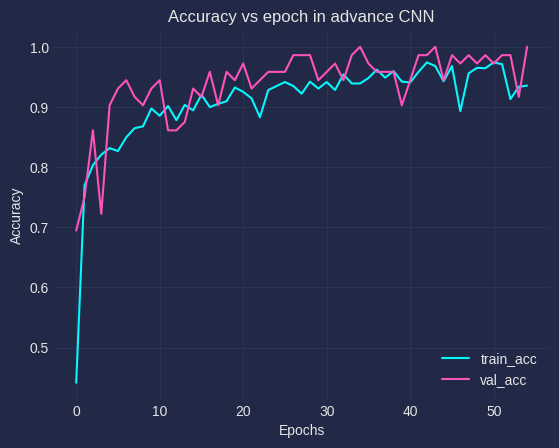

In [107]:
# plt.style.use('cyberpunk')
plt.plot(advance_history['train_acc'], label="train_acc")
plt.plot(advance_history['val_acc'], label="val_acc")
# mplcyberpunk.add_glow_effects()
plt.title("Accuracy vs epoch in advance CNN")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

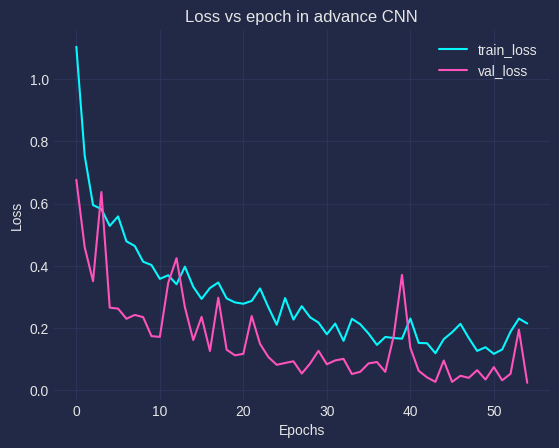

In [108]:
plt.plot(advance_history['train_loss'], label="train_loss")
plt.plot(advance_history['val_loss'], label="val_loss")
plt.title("Loss vs epoch in advance CNN")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Comparision

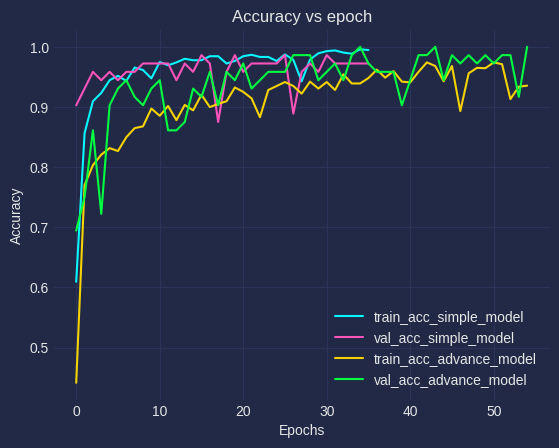

In [109]:
plt.plot(history['train_acc'], label="train_acc_simple_model")
plt.plot(history['val_acc'], label="val_acc_simple_model")
plt.plot(advance_history['train_acc'], label="train_acc_advance_model")
plt.plot(advance_history['val_acc'], label="val_acc_advance_model")
plt.title("Accuracy vs epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()